# **FedEx Logistics Performance Analysis**
*Exploratory Data Analysis of the SCMS Delivery History dataset*

##### **Project Type**    - EDA
##### **Contribution**    - Individual
##### **Team Member 1 -** Mangla Ram

# **Project Summary -**

This project studies how reliably FedEx Logistics delivers pharmaceutical and health-commodity shipments for a global supply chain programme. The dataset has **10,324 shipment lines** to **43 destination countries**, delivered between 2006 and 2015, with 33 columns covering the purchase order, the shipping route, the vendor agreement (INCO term), the planned and actual delivery dates, the product, the weight, the freight cost and the insurance cost.

The business goal is to find out **where and why deliveries miss their scheduled date**, so that planners can cut delays and control freight and insurance cost. A shipment is called *delayed* when the delivered-to-client date is later than the scheduled delivery date. The brief lists six questions: does the managing team matter, does the shipment mode matter (asked twice, as likelihood and as frequency), do some destination countries suffer more delays, does the time between PO and scheduled delivery matter, does the INCO term matter, and does heavier cargo cost more to insure.

**Data preparation.** The file has no duplicate rows and only three columns with true nulls (shipment mode, dosage, insurance). The harder problem was hidden missing data: 3,952 weight cells and 4,126 freight cells contain text instead of numbers. About 2,445 of them say "See ASN-... (ID#:...)" and point to another row, so I resolved those references and recovered 2,319 weights and 2,340 freight values. The rest ("Weight Captured Separately", "Freight Included in Commodity Cost") stay empty on purpose, because filling them would invent numbers. Dates came in two formats and were parsed separately. I then built delay days, a delivery status, lead time, freight per kilogram and a few tidy categorical columns.

**What the analysis found.** Overall **88.5%** of shipments arrive on or before the scheduled date and **11.5%** are late; late shipments are a median of 12 days late, with a long tail up to 192 days. The strongest driver is the fulfilment route: shipments sent **from the regional distribution centre are delayed 17.2% of the time against 5.3% for direct drops**. Shipment mode looks important in raw numbers, but it changes meaning with the route. Trucks look slow overall (16.1% late), yet on direct drops they are the most reliable mode (1.2%), while from the RDC they are the worst (23.2%). Destination matters too: Congo DRC (24.9%), Mozambique (18.4%) and Zambia (15.8%) are the worst of the large markets, Vietnam (0.9%) the best. INCO terms FCA and CIP are almost never late. Heavier shipments do cost more to insure (Spearman 0.68), but this is mostly because they carry more value: insurance tracks line value almost perfectly (Spearman 0.99) and weight adds nothing once value is controlled.

**Statistics and honesty about limits.** Each question was tested (chi-square, Fisher's exact, Mann-Whitney, Spearman, plus a logistic regression). The model explains only a small part of delay behaviour (pseudo R-squared 0.08), and 61% of shipments show a delivery date exactly equal to the schedule, which looks like a recording habit. The results describe patterns, not proven causes.

**Recommendations.** Fix the RDC and regional trucking leg first, add buffer time for DRC, Mozambique and Zambia, prefer FCA/CIP style terms where possible, and review recording of delivery dates.

# **GitHub Link -**

**GitHub repository:** https://github.com/ram-mangla/fedex-logistics-eda-capstone

*(Repository contents: this notebook, `README.md`, and a link to the dataset.)*

# **Problem Statement**

**FedEx Logistics moves purchase-order shipments between vendors and clients in many countries. Some shipments reach the client after the scheduled delivery date. Using the delivery history, find which factors (managing team, shipment mode, destination country, vendor INCO term, order lead time, fulfilment route) are linked to late delivery, and how weight relates to insurance cost, so that logistics operations can be made faster and cheaper.**

#### **Define Your Business Objective?**
Raise the on-time delivery rate (today **88.5%**) by finding the route, mode, country and contract combinations that produce most of the **1,186 delayed shipments**, and give stakeholders concrete rules to plan buffer time, choose shipment modes and set insurance expectations.

#### **Hypotheses / Assumptions (listed before looking at the charts)**
| # | Question from the brief | Working hypothesis |
|---|---|---|
| H1 | Do shipments managed by specific teams (PMO - US vs others) deliver on time more often? | The central PMO - US team is the benchmark and no other team is better. |
| H2 | Does shipment mode change the likelihood of meeting the scheduled date? | Air is the most reliable, Ocean and Truck the least. |
| H3 | Do shipments to some countries see more delays? | Yes, delays concentrate in a few hard-to-reach countries. |
| H4 | Does a longer gap between PO sent and scheduled delivery change on-time performance? | A longer lead time should make delay less likely. |
| H5 | Does the INCO term used change vendor delivery performance? | Terms where the vendor controls the whole journey (DDP) should be more reliable. |
| H6 | Are heavier shipments more likely to carry higher insurance cost? | Yes, insurance should rise with weight. |
| H7 | Does mode on its own predict on-time frequency (second wording of H2)? | Same as H2; checked also after controlling for the fulfilment route. |

**Assumptions:** a shipment is **delayed** when `Delivered to Client Date > Scheduled Delivery Date`, **on time** when equal, **early** when earlier. "Met schedule" means on time or early. Missing values are never filled with invented numbers; they are either recovered from the dataset itself or left empty and excluded from the specific calculation.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Core libraries for data handling, statistics and visualisation
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")                      # keep the notebook output clean
pd.set_option("display.max_columns", 50)               # show every column when printing a DataFrame
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# One consistent look for every matplotlib / seaborn chart
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Delayed": "#D1495B", "On time": "#2E86AB", "Early": "#7FB069"}   # semantic colours reused everywhere
BLUE, RED, GREY = "#2E86AB", "#D1495B", "#8D99AE"
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

### Dataset Loading

In [2]:
# Load the SCMS delivery history file.
# Order of attempts: (1) file next to the notebook, (2) AlmaBetter's shared Google Drive copy via gdown, (3) manual upload in Colab.
import os
FILE_NAME = "SCMS_Delivery_History_Dataset.csv"
DRIVE_ID = "1G3sg45qaljQ9w-bB5i4-n7QAM59cR4xN"          # file id from the project's dataset link

def load_dataset(path=FILE_NAME):
    """Return the raw dataset as a DataFrame, downloading it when it is not already present."""
    if not os.path.exists(path):
        try:
            import gdown
            gdown.download(id=DRIVE_ID, output=path, quiet=True)
        except Exception as err:                         # network / permission problem -> fall back to upload
            print("Drive download failed:", err)
    if not os.path.exists(path):
        from google.colab import files                   # only works inside Colab
        path = list(files.upload().keys())[0]
    return pd.read_csv(path)

raw = load_dataset()
print("Loaded:", raw.shape)

Loaded: (10324, 33)


### Dataset First View

In [3]:
# First and last rows of the raw data (transposed so that all 33 columns fit on screen)
raw.head(3).T

,0,1,2
ID,1,3,4
Project Code,100-CI-T01,108-VN-T01,100-CI-T01
PQ #,Pre-PQ Process,Pre-PQ Process,Pre-PQ Process
PO / SO #,SCMS-4,SCMS-13,SCMS-20
ASN/DN #,ASN-8,ASN-85,ASN-14
Country,Côte d'Ivoire,Vietnam,Côte d'Ivoire
Managed By,PMO - US,PMO - US,PMO - US
Fulfill Via,Direct Drop,Direct Drop,Direct Drop
Vendor INCO Term,EXW,EXW,FCA
Shipment Mode,Air,Air,Air


In [4]:
raw.tail(2).T

,10322,10323
ID,86822,86823
Project Code,200-ZW-T30,103-ZW-T30
PQ #,FPQ-16523,FPQ-15197
PO / SO #,SO-51680,SO-50022
ASN/DN #,DN-4334,DN-4336
Country,Zimbabwe,Zimbabwe
Managed By,PMO - US,PMO - US
Fulfill Via,From RDC,From RDC
Vendor INCO Term,N/A - From RDC,N/A - From RDC
Shipment Mode,Truck,Truck


### Dataset Rows & Columns count

In [5]:
# Dataset Rows & Columns count
rows, cols = raw.shape
print(f"Rows: {rows:,}  |  Columns: {cols}")

Rows: 10,324  |  Columns: 33


### Dataset Information

In [6]:
# Data types, non-null counts and memory use
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ID                            10324 non-null  int64  
 1   Project Code                  10324 non-null  str    
 2   PQ #                          10324 non-null  str    
 3   PO / SO #                     10324 non-null  str    
 4   ASN/DN #                      10324 non-null  str    
 5   Country                       10324 non-null  str    
 6   Managed By                    10324 non-null  str    
 7   Fulfill Via                   10324 non-null  str    
 8   Vendor INCO Term              10324 non-null  str    
 9   Shipment Mode                 9964 non-null   str    
 10  PQ First Sent to Client Date  10324 non-null  str    
 11  PO Sent to Vendor Date        10324 non-null  str    
 12  Scheduled Delivery Date       10324 non-null  str    
 13  Delivered to

#### Duplicate Values

In [7]:
# A duplicated shipment would be counted twice in every rate, so check both full rows and the ID key
print("Fully duplicated rows:", raw.duplicated().sum())
print("Duplicated IDs        :", raw["ID"].duplicated().sum())

Fully duplicated rows: 0
Duplicated IDs        : 0


#### Missing Values/Null Values

In [8]:
# Real nulls (NaN) per column
nulls = raw.isna().sum()
nulls = nulls[nulls > 0].to_frame("missing_cells")
nulls["missing_pct"] = nulls["missing_cells"] / len(raw) * 100
display(nulls)

# Hidden missing values: the cell is filled but holds text where a number or date should be
hidden = pd.DataFrame({
    "Weight (Kilograms)":            [pd.to_numeric(raw["Weight (Kilograms)"], errors="coerce").isna().sum()],
    "Freight Cost (USD)":            [pd.to_numeric(raw["Freight Cost (USD)"], errors="coerce").isna().sum()],
    "PO Sent to Vendor Date":        [pd.to_datetime(raw["PO Sent to Vendor Date"], format="%m/%d/%y", errors="coerce").isna().sum()],
    "PQ First Sent to Client Date":  [pd.to_datetime(raw["PQ First Sent to Client Date"], format="%m/%d/%y", errors="coerce").isna().sum()],
}, index=["cells that are text, not numbers/dates"]).T
hidden["pct_of_rows"] = hidden.iloc[:, 0] / len(raw) * 100
display(hidden)
print("What the text values are:")
print(raw["Weight (Kilograms)"].where(pd.to_numeric(raw["Weight (Kilograms)"], errors="coerce").isna()).str.replace(r"\(ID#:\d+\)", "(ID#:n)", regex=True).str.replace(r"(ASN|DN)-\d+", r"\1-n", regex=True).value_counts().head(4))

,missing_cells,missing_pct
Shipment Mode,360,3.49
Dosage,1736,16.82
Line Item Insurance (USD),287,2.78


,"cells that are text, not numbers/dates",pct_of_rows
Weight (Kilograms),3952,38.28
Freight Cost (USD),4126,39.97
PO Sent to Vendor Date,5732,55.52
PQ First Sent to Client Date,2681,25.97


What the text values are:
Weight (Kilograms)
See DN-n (ID#:n)              1937
Weight Captured Separately    1507
See ASN-n (ID#:n)              508
Name: count, dtype: int64


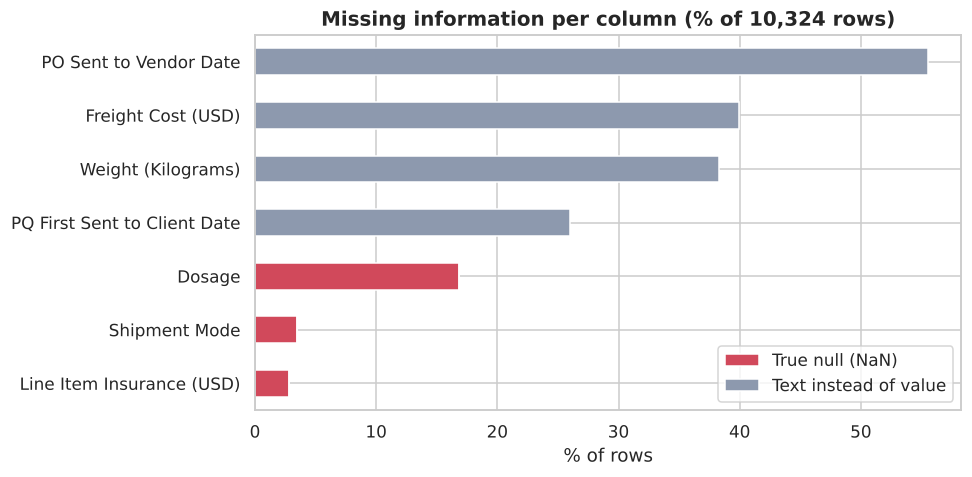

In [9]:
# Visualizing the missing values: true nulls + hidden text-missing, as % of all rows
miss = pd.concat([nulls["missing_pct"].rename("True null (NaN)"), (hidden["pct_of_rows"]).rename("Text instead of value")], axis=1).fillna(0)
miss = miss.loc[miss.sum(axis=1).sort_values().index]
ax = miss.plot(kind="barh", stacked=True, figsize=(9, 4.5), color=[RED, GREY])
ax.set(title="Missing information per column (% of 10,324 rows)", xlabel="% of rows", ylabel="")
plt.tight_layout(); plt.show()

### What did you know about your dataset?

* **10,324 rows x 33 columns.** One row is one line item of a purchase order shipped to a client in one of 43 countries, delivered between 2006 and 2015.
* **No duplicate rows and no duplicate IDs**, so no row needs removing.
* **Only three columns have real nulls:** Shipment Mode (360), Dosage (1,736, mostly test kits that simply have no dosage) and Line Item Insurance (287).
* **The bigger problem is hidden missing data.** Weight has 3,952 text cells and Freight Cost has 4,126. Most say `See ASN-... (ID#:...)`, a pointer to another row. The others explain why the value is absent (`Weight Captured Separately`, `Freight Included in Commodity Cost`, `Invoiced Separately`).
* **Two date formats** are mixed (`2-Jun-06` and `9/11/14`) and two date columns also hold labels such as `Pre-PQ Process` and `N/A - From RDC`.
* **Two fulfilment routes exist:** `Direct Drop` (vendor ships to client, 4,920 rows) and `From RDC` (shipped from a regional distribution centre, 5,404 rows). RDC rows have no PO date and no INCO term by design.

## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
list(raw.columns)

['ID',
 'Project Code',
 'PQ #',
 'PO / SO #',
 'ASN/DN #',
 'Country',
 'Managed By',
 'Fulfill Via',
 'Vendor INCO Term',
 'Shipment Mode',
 'PQ First Sent to Client Date',
 'PO Sent to Vendor Date',
 'Scheduled Delivery Date',
 'Delivered to Client Date',
 'Delivery Recorded Date',
 'Product Group',
 'Sub Classification',
 'Vendor',
 'Item Description',
 'Molecule/Test Type',
 'Brand',
 'Dosage',
 'Dosage Form',
 'Unit of Measure (Per Pack)',
 'Line Item Quantity',
 'Line Item Value',
 'Pack Price',
 'Unit Price',
 'Manufacturing Site',
 'First Line Designation',
 'Weight (Kilograms)',
 'Freight Cost (USD)',
 'Line Item Insurance (USD)']

In [11]:
# Dataset Describe: numeric summary first, then categorical columns
display(raw.describe().T)
raw.describe(include="object").T.iloc[:, :3]

,count,mean,std,min,25%,50%,75%,max
ID,"10,324.00","51,098.97","31,944.33",1.00,"12,795.75","57,540.50","83,648.25","86,823.00"
Unit of Measure (Per Pack),"10,324.00",77.99,76.58,1.00,30.00,60.00,90.00,"1,000.00"
Line Item Quantity,"10,324.00","18,332.53","40,035.30",1.00,408.00,"3,000.00","17,039.75","619,999.00"
Line Item Value,"10,324.00","157,650.57","345,292.07",0.00,"4,314.59","30,471.47","166,447.14","5,951,990.40"
Pack Price,"10,324.00",21.91,45.61,0.00,4.12,9.30,23.59,"1,345.64"
Unit Price,"10,324.00",0.61,3.28,0.00,0.08,0.16,0.47,238.65
Line Item Insurance (USD),"10,037.00",240.12,500.19,0.00,6.51,47.04,252.40,"7,708.44"


,count,unique,top
Project Code,10324,142,116-ZA-T30
PQ #,10324,1237,Pre-PQ Process
PO / SO #,10324,6233,SCMS-199289
ASN/DN #,10324,7030,ASN-19166
Country,10324,43,South Africa
Managed By,10324,4,PMO - US
Fulfill Via,10324,2,From RDC
Vendor INCO Term,10324,8,N/A - From RDC
Shipment Mode,9964,4,Air
PQ First Sent to Client Date,10324,765,Pre-PQ Process


### Variables Description

| Column | Meaning |
|---|---|
| ID | Unique identifier of each logistics record |
| Project Code | Project / initiative the shipment belongs to |
| PQ # | Price quotation reference (`Pre-PQ Process` = no quotation) |
| PO / SO # | Purchase order or sales order number |
| ASN/DN # | Advance shipment notice or delivery note reference |
| Country | Destination country |
| Managed By | Team managing the shipment (PMO - US or a field office) |
| Fulfill Via | `Direct Drop` (vendor to client) or `From RDC` (regional distribution centre) |
| Vendor INCO Term | Incoterm of the vendor agreement (EXW, FCA, DDP, CIP ...) |
| Shipment Mode | Air, Air Charter, Ocean or Truck |
| PQ First Sent to Client Date | Date the price quotation was first sent |
| PO Sent to Vendor Date | Date the purchase order went to the vendor |
| Scheduled Delivery Date | Planned delivery date |
| Delivered to Client Date | Actual delivery date |
| Delivery Recorded Date | Date the delivery was entered in the system |
| Product Group / Sub Classification | Product family (ARV, HRDT, ANTM, ACT, MRDT) and a finer class |
| Vendor / Manufacturing Site | Supplier and the site that made the goods |
| Item Description / Molecule/Test Type / Brand | What was shipped |
| Dosage / Dosage Form | Strength and form (test kit, tablet, oral suspension ...) |
| Unit of Measure (Per Pack) | Units per pack |
| Line Item Quantity / Value | Units shipped and their total value in USD |
| Pack Price / Unit Price | Price per pack and per unit |
| First Line Designation | Whether this is the first line of the order |
| Weight (Kilograms) | Shipment weight |
| Freight Cost (USD) | Cost of shipping the item |
| Line Item Insurance (USD) | Insurance cost for the line item |

### Check Unique Values for each variable.

In [12]:
# Unique values per column, with the three most common values to spot odd labels
summary = pd.DataFrame({
    "unique_values": raw.nunique(),
    "top_values": [", ".join(map(str, raw[c].value_counts().head(3).index))[:70] for c in raw.columns],
})
summary

,unique_values,top_values
ID,10324,"1, 3, 4"
Project Code,142,"116-ZA-T30, 104-CI-T30, 151-NG-T30"
PQ #,1237,"Pre-PQ Process, FPQ-14942, FPQ-12522"
PO / SO #,6233,"SCMS-199289, SCMS-199283, SCMS-183950"
ASN/DN #,7030,"ASN-19166, ASN-24415, ASN-23875"
Country,43,"South Africa, Nigeria, Côte d'Ivoire"
Managed By,4,"PMO - US, South Africa Field Office, Haiti Fie..."
Fulfill Via,2,"From RDC, Direct Drop"
Vendor INCO Term,8,"N/A - From RDC, EXW, DDP"
Shipment Mode,4,"Air, Truck, Air Charter"


## ***3. Data Wrangling***

### Data Wrangling Code

In [13]:
# ---------- Data wrangling, written as small reusable functions ----------
DATE_COLS_DMY = {"Scheduled Delivery Date": "sched_date", "Delivered to Client Date": "delivered_date", "Delivery Recorded Date": "recorded_date"}
DATE_COLS_MDY = {"PQ First Sent to Client Date": "pq_sent_date", "PO Sent to Vendor Date": "po_sent_date"}

def parse_dates(df):
    """Dates arrive in two formats (d-Mon-yy and m/d/yy). Text such as 'Pre-PQ Process' becomes NaT and is flagged separately."""
    for col, new in DATE_COLS_DMY.items():
        df[new] = pd.to_datetime(df[col], format="%d-%b-%y", errors="coerce")
    for col, new in DATE_COLS_MDY.items():
        df[new] = pd.to_datetime(df[col], format="%m/%d/%y", errors="coerce")
    df["pre_pq_process"] = df["PQ First Sent to Client Date"].eq("Pre-PQ Process")   # shipment never went through a PQ
    return df

def resolve_reference(df, col):
    """Some cells say 'See ASN-123 (ID#:456)': the real number sits on another row.
    Copy that row's value when it is numeric, otherwise leave the cell empty."""
    text = df[col]
    own = pd.to_numeric(text, errors="coerce")
    ref_id = text.str.extract(r"ID#:(\d+)")[0].astype(float)
    lookup = pd.to_numeric(df.set_index("ID")[col], errors="coerce")
    return own.fillna(ref_id.map(lookup))

def wrangle(raw):
    """Full cleaning + feature engineering pipeline. Returns a new DataFrame (raw is never modified)."""
    df = parse_dates(raw.copy())

    # --- delivery performance (the target of the whole study) ---
    df["delay_days"] = (df["delivered_date"] - df["sched_date"]).dt.days           # + late, - early
    df["delivery_status"] = np.select([df["delay_days"] > 0, df["delay_days"] < 0], ["Delayed", "Early"], default="On time")
    df["is_delayed"] = (df["delay_days"] > 0).astype(int)

    # --- lead time = days between PO sent to vendor and the scheduled delivery (only exists for Direct Drop orders) ---
    df["lead_days"] = (df["sched_date"] - df["po_sent_date"]).dt.days
    df.loc[df["lead_days"] < 0, "lead_days"] = np.nan                               # a PO cannot be sent after delivery -> invalid
    df["lead_band"] = pd.cut(df["lead_days"], [-1, 30, 60, 90, 120, 180, 1000],
                             labels=["0-30d", "31-60d", "61-90d", "91-120d", "121-180d", "180d+"])

    # --- numeric columns hidden inside text ---
    df["weight_kg"] = resolve_reference(df, "Weight (Kilograms)")
    df["freight_usd"] = resolve_reference(df, "Freight Cost (USD)")
    df["freight_included"] = df["Freight Cost (USD)"].eq("Freight Included in Commodity Cost")   # keep the reason, not just NaN
    df["freight_per_kg"] = df["freight_usd"] / df["weight_kg"].where(df["weight_kg"] > 0)
    df = df.rename(columns={"Line Item Insurance (USD)": "insurance_usd", "Line Item Value": "line_value", "Line Item Quantity": "quantity",
                            "Unit Price": "unit_price", "Pack Price": "pack_price"})
    df["insurance_pct_value"] = df["insurance_usd"] / df["line_value"].where(df["line_value"] > 0) * 100

    # --- categorical tidy-up ---
    df["shipment_mode"] = df["Shipment Mode"].fillna("Not recorded")
    df["fulfil_via"] = df["Fulfill Via"]
    df["inco_term"] = df["Vendor INCO Term"].replace({"N/A - From RDC": "From RDC (no INCO)"})
    df["managed_by"] = np.where(df["Managed By"].eq("PMO - US"), "PMO - US", "Field office")   # 3 field offices combined (only 59 rows)
    df["country"] = df["Country"]
    df["dosage"] = df["Dosage"].fillna("Not applicable")                                       # test kits have no dosage
    df["product_group"] = df["Product Group"]
    df["delivery_year"] = df["delivered_date"].dt.year
    return df

df = wrangle(raw)
print("Wrangled:", df.shape)

Wrangled: (10324, 57)


In [14]:
# ---------- Small statistical helpers reused by many charts ----------
def wilson_ci(delayed, n, z=1.96):
    """95% Wilson confidence interval for a proportion (better than the normal approximation for small n)."""
    p = delayed / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def delay_table(df, by, min_n=1):
    """Delay rate (%) per category with its 95% confidence interval."""
    g = df.groupby(by, observed=True)["is_delayed"].agg(delayed="sum", shipments="count").reset_index()
    g["delay_rate"] = g["delayed"] / g["shipments"] * 100
    ci = g.apply(lambda r: wilson_ci(r["delayed"], r["shipments"]), axis=1, result_type="expand")
    g["lo"], g["hi"] = ci[0] * 100, ci[1] * 100
    return g[g["shipments"] >= min_n].sort_values("delay_rate", ascending=False).reset_index(drop=True)

def chi_square(df, by):
    """Chi-square test of independence between a category and the delayed / not-delayed outcome."""
    table = pd.crosstab(df[by], df["is_delayed"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return {"chi2": chi2, "p": p, "dof": dof, "cramers_v": cramers_v}

In [15]:
# Quick validation of the wrangled data: every rule below must hold, otherwise the notebook stops
assert len(df) == len(raw), "wrangling must not drop rows"
assert df["delay_days"].notna().all(), "every shipment has both dates"
assert set(df["delivery_status"]) == {"Early", "On time", "Delayed"}
assert (df["lead_days"].dropna() >= 0).all(), "negative lead times were removed"
print("All checks passed.")
df[["ID", "country", "shipment_mode", "fulfil_via", "inco_term", "sched_date", "delivered_date", "delay_days", "delivery_status", "lead_days", "weight_kg", "freight_usd", "insurance_usd"]].head()

All checks passed.


,ID,country,shipment_mode,fulfil_via,inco_term,sched_date,delivered_date,delay_days,delivery_status,lead_days,weight_kg,freight_usd,insurance_usd
0,1,Côte d'Ivoire,Air,Direct Drop,EXW,2006-06-02,2006-06-02,0,On time,NaN,13.00,780.34,NaN
1,3,Vietnam,Air,Direct Drop,EXW,2006-11-14,2006-11-14,0,On time,NaN,358.00,"4,521.50",NaN
2,4,Côte d'Ivoire,Air,Direct Drop,FCA,2006-08-27,2006-08-27,0,On time,NaN,171.00,"1,653.78",NaN
3,15,Vietnam,Air,Direct Drop,EXW,2006-09-01,2006-09-01,0,On time,NaN,"1,855.00","16,007.06",NaN
4,16,Vietnam,Air,Direct Drop,EXW,2006-08-11,2006-08-11,0,On time,NaN,"7,590.00","45,450.08",NaN


In [16]:
# Outlier check on the money / weight columns (IQR rule). Outliers are FLAGGED and kept: big shipments are real business, not errors.
for col in ["weight_kg", "freight_usd", "insurance_usd", "line_value"]:
    s = df[col].dropna(); q1, q3 = s.quantile([.25, .75]); upper = q3 + 1.5 * (q3 - q1)
    print(f"{col:14s} median {s.median():>12,.0f} | 99th pct {s.quantile(.99):>14,.0f} | max {s.max():>14,.0f} | above IQR fence: {(s > upper).mean():.1%}")

weight_kg      median        1,303 | 99th pct         47,387 | max        857,354 | above IQR fence: 10.3%
freight_usd    median        6,759 | 99th pct         94,899 | max        289,653 | above IQR fence: 7.3%
insurance_usd  median           47 | 99th pct          2,455 | max          7,708 | above IQR fence: 11.1%
line_value     median       30,471 | 99th pct      1,592,935 | max      5,951,990 | above IQR fence: 10.9%


### What all manipulations have you done and insights you found?

**Manipulations**
1. Parsed both date formats; text labels became empty dates and a `pre_pq_process` flag was kept.
2. **Resolved "See ASN-... (ID#:...)" references** by copying the value from the referenced row: 2,319 weights and 2,340 freight costs recovered. Values that are explained by text (`Freight Included in Commodity Cost`) were not guessed.
3. Created the target: `delay_days = delivered - scheduled`, then `delivery_status` (Early / On time / Delayed) and `is_delayed`.
4. Created `lead_days` (PO sent to scheduled delivery). Four negative values (PO after delivery) were removed as invalid.
5. Created `freight_per_kg` and `insurance_pct_value`; renamed awkward columns; grouped the three field offices (59 rows) into one `Field office` label; filled Dosage with `Not applicable` for test kits; labelled the 360 missing modes as `Not recorded` instead of dropping them.
6. **Outliers were flagged, not removed.** Very large shipments are genuine, so charts use log scales instead.

**Insights found while cleaning**
* 61% of shipments have `delay_days == 0`. A share this high looks like delivery dates being recorded as the schedule date. This is the biggest data-quality warning of the project and is repeated in the conclusion.
* Direct Drop is the only route with a PO date, so lead-time analysis covers 4,588 shipments, not all 10,324.
* Insurance is on average about 0.16% of line value, a very regular ratio.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

*Following the UBM rule: Univariate (charts 1-5), Bivariate (charts 6-15) and Multivariate (charts 16-19).*

### **U - Univariate analysis**

#### Chart - 1 : Overall delivery performance

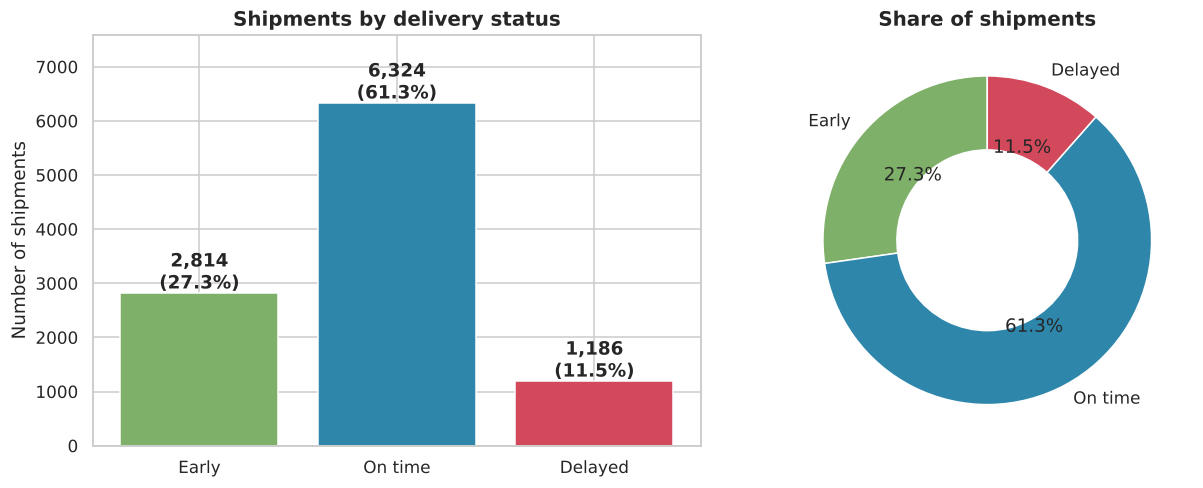

In [17]:
# Chart - 1 : Overall delivery performance
order = ["Early", "On time", "Delayed"]
counts = df["delivery_status"].value_counts().reindex(order)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].bar(counts.index, counts.values, color=[PALETTE[s] for s in counts.index])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 90, f"{v:,}\n({v / len(df):.1%})", ha="center", fontweight="bold")   # count + share on each bar
ax[0].set(title="Shipments by delivery status", ylabel="Number of shipments", ylim=(0, counts.max() * 1.2))
ax[1].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90, colors=[PALETTE[s] for s in counts.index], wedgeprops=dict(width=0.45))
ax[1].set_title("Share of shipments")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
A status variable with only three values is best shown as bars (exact counts are easy to read) next to a donut (share of the whole is obvious at a glance).

##### 2. What is/are the insight(s) found from the chart?
* **88.5%** of shipments meet the schedule: 61.3% on time and 27.3% early.
* **1,186 shipments (11.5%)** are delayed.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
Positive: the baseline is healthy, so the problem is concentrated, not general. Negative: one delayed shipment in nine involves life-saving health commodities, so even 11% is costly. The study therefore looks for *where* the delays sit.

#### Chart - 2 : How late are the late shipments?

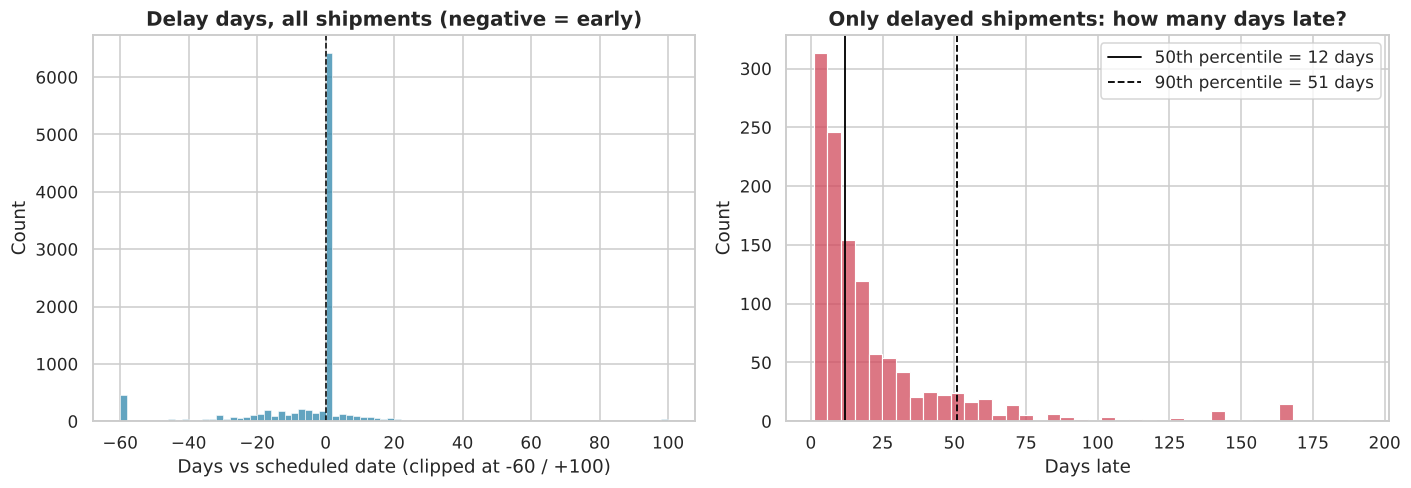

count   1,186.00
mean       21.40
std        28.50
min         1.00
25%         5.00
50%        12.00
75%        24.80
max       192.00
Name: delay_days, dtype: float64


In [18]:
# Chart - 2 : Distribution of delay days (clipped so the long tail does not hide the shape)
clip = df["delay_days"].clip(-60, 100)
late = df.loc[df["is_delayed"] == 1, "delay_days"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
sns.histplot(clip, bins=80, color=BLUE, ax=ax[0])
ax[0].axvline(0, color="black", ls="--", lw=1); ax[0].set(title="Delay days, all shipments (negative = early)", xlabel="Days vs scheduled date (clipped at -60 / +100)")
sns.histplot(late, bins=40, color=RED, ax=ax[1])
for q, ls in [(0.5, "-"), (0.9, "--")]:
    ax[1].axvline(late.quantile(q), color="black", ls=ls, lw=1.2, label=f"{int(q * 100)}th percentile = {late.quantile(q):.0f} days")
ax[1].set(title="Only delayed shipments: how many days late?", xlabel="Days late"); ax[1].legend()
plt.tight_layout(); plt.show()
print(late.describe().round(1))

##### 1. Why did you pick the specific chart?
A histogram shows the full shape of a numeric variable. Two panels are used because the huge spike at zero would hide the story of the late shipments.

##### 2. What is/are the insight(s) found from the chart?
* A very tall spike at exactly 0 days (61% of all shipments).
* For delayed shipments the distribution is strongly right-skewed: **median 12 days, 90th percentile 51 days, maximum 192 days**.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
Positive: most delays are short, so a modest buffer of about two weeks absorbs half of them. Negative: the long tail (a tenth of delays exceed 51 days) is where stock-outs happen. Averages would hide this, so planning should use percentiles.

#### Chart - 3 : Shipment mode and fulfilment route mix

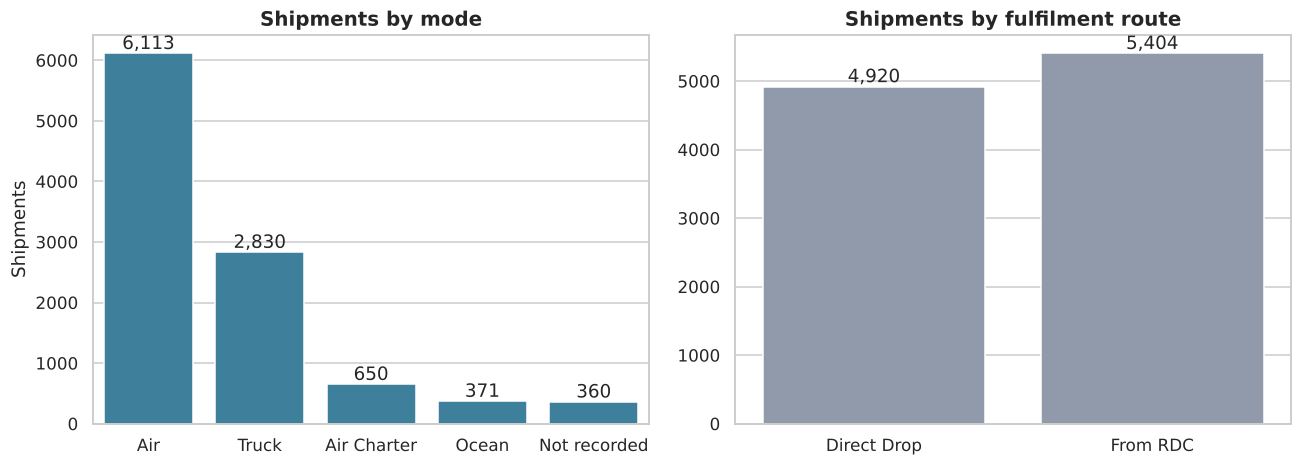

In [19]:
# Chart - 3 : How shipments are moved
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
order = df["shipment_mode"].value_counts().index
sns.countplot(data=df, x="shipment_mode", order=order, color=BLUE, ax=ax[0])
for p in ax[0].patches: ax[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax[0].set(title="Shipments by mode", xlabel="", ylabel="Shipments")
sns.countplot(data=df, x="fulfil_via", color=GREY, ax=ax[1])
for p in ax[1].patches: ax[1].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax[1].set(title="Shipments by fulfilment route", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
Both variables are categories, so count bars with labels are the clearest way to compare their sizes.

##### 2. What is/are the insight(s) found from the chart?
* Air carries 59% of shipments, then Truck 27%, Air Charter 6%, Ocean 4%.
* The two routes are almost evenly split: 52% From RDC, 48% Direct Drop.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
Because Air carries most of the volume, any small change in Air reliability moves the overall rate more than a big change in Ocean. Ocean has too few shipments (371) for firm conclusions at country level.

#### Chart - 4 : Weight and freight cost distributions

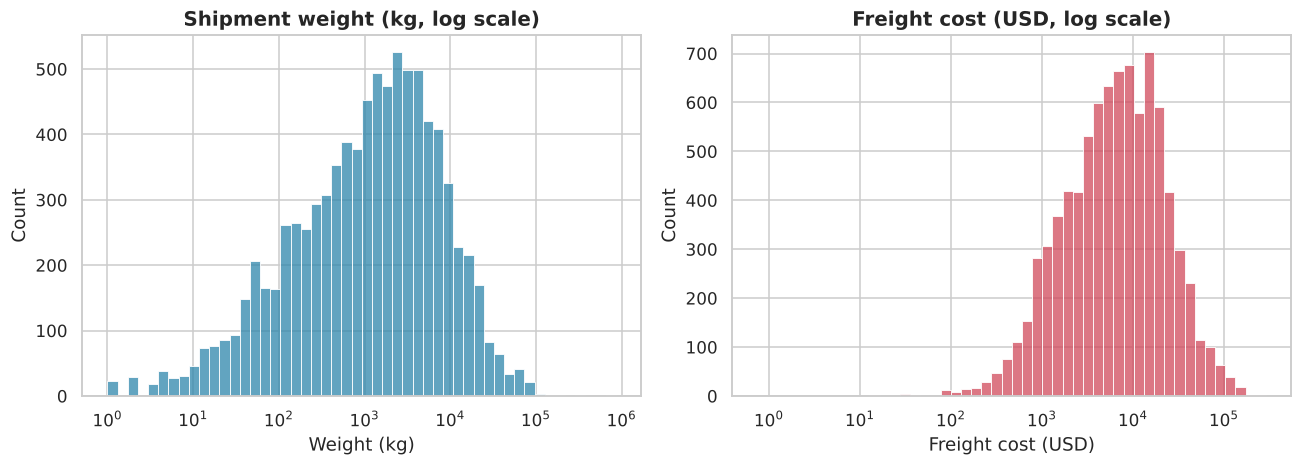

       weight_kg  freight_usd
count   8,691.00     8,538.00
mean    4,464.00    12,642.00
std    13,372.00    18,190.00
min         0.00         1.00
25%       275.00     2,599.00
50%     1,303.00     6,759.00
75%     4,364.00    15,571.00
max   857,354.00   289,653.00


In [20]:
# Chart - 4 : Weight and freight cost (log scale because a few shipments are enormous)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
sns.histplot(df["weight_kg"].dropna().loc[lambda s: s > 0], log_scale=True, bins=50, color=BLUE, ax=ax[0])
ax[0].set(title="Shipment weight (kg, log scale)", xlabel="Weight (kg)")
sns.histplot(df["freight_usd"].dropna().loc[lambda s: s > 0], log_scale=True, bins=50, color=RED, ax=ax[1])
ax[1].set(title="Freight cost (USD, log scale)", xlabel="Freight cost (USD)")
plt.tight_layout(); plt.show()
print(df[["weight_kg", "freight_usd"]].describe().round(0))

##### 1. Why did you pick the specific chart?
Weight and freight span several orders of magnitude, so a linear histogram would show one bar. A log-scaled histogram shows the real shape.

##### 2. What is/are the insight(s) found from the chart?
* Weight: median 1,303 kg, but the maximum is 857,354 kg.
* Freight cost: median $6,759, maximum $289,653.
* Both are roughly bell-shaped on a log scale, which means most shipments are small and a few are very large.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
Positive: a log scale makes weight and cost comparable across modes. Negative: a small group of very heavy shipments carries a large share of total freight spend, so freight savings should focus on them.

#### Chart - 5 : Top destination countries

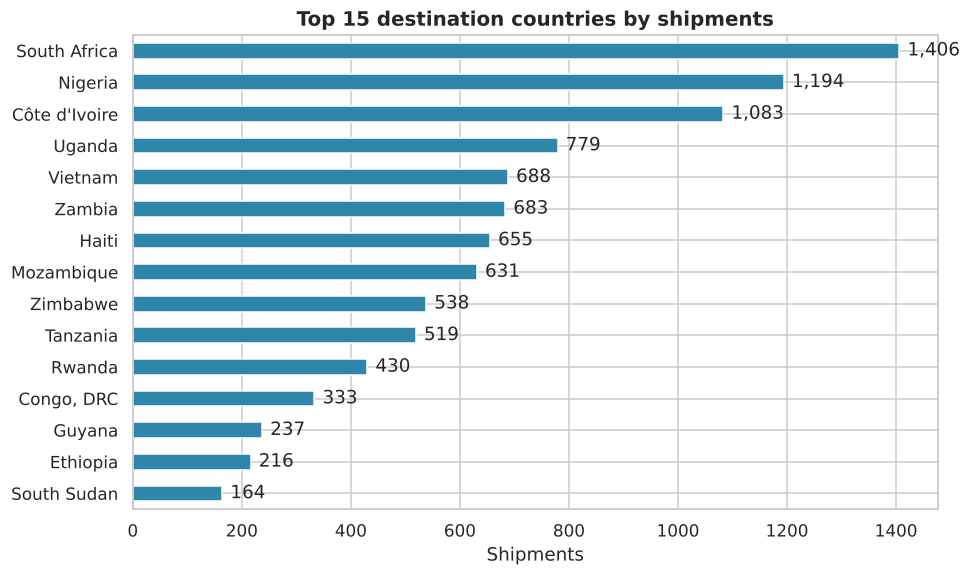

Top 5 countries carry 50% of all shipments


In [21]:
# Chart - 5 : Where the volume goes
top = df["country"].value_counts().head(15).sort_values()
ax = top.plot(kind="barh", color=BLUE, figsize=(9, 5.4))
for i, v in enumerate(top.values): ax.text(v + 15, i, f"{v:,}", va="center")
ax.set(title="Top 15 destination countries by shipments", xlabel="Shipments", ylabel="")
plt.tight_layout(); plt.show()
print(f"Top 5 countries carry {df['country'].value_counts().head(5).sum() / len(df):.0%} of all shipments")

##### 1. Why did you pick the specific chart?
A horizontal sorted bar chart is the standard way to rank many categories with long labels.

##### 2. What is/are the insight(s) found from the chart?
* South Africa (1,406), Nigeria (1,194), Côte d'Ivoire (1,083), Uganda (779) and Vietnam (688) lead.
* The top 5 countries carry 50% of shipments.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
Positive: improvement effort on a handful of lanes reaches most of the volume. Negative: 27 of 43 countries have fewer than 100 shipments, so their delay rates are unstable and are treated with caution in later charts.

### **B - Bivariate analysis**

#### Chart - 6 : Delay rate by shipment mode  (H2 / H7)

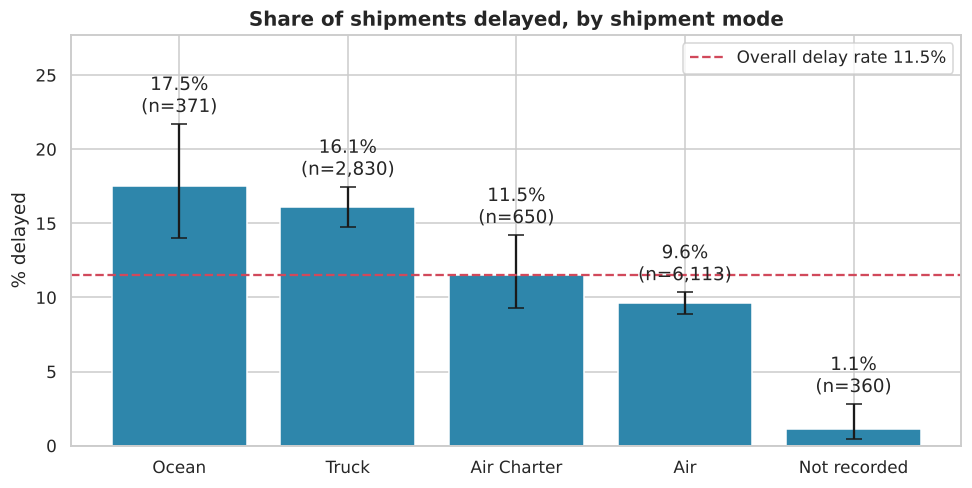

Chi-square test: chi2 = 131.4, dof = 4, p = 1.95e-27, Cramer's V = 0.11


In [22]:
# Chart - 6 : Delay rate by shipment mode with 95% confidence intervals
t = delay_table(df, "shipment_mode")
overall = df["is_delayed"].mean() * 100
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.bar(t["shipment_mode"], t["delay_rate"], color=BLUE, yerr=[t["delay_rate"] - t["lo"], t["hi"] - t["delay_rate"]], capsize=5)
ax.axhline(overall, color=RED, ls="--", label=f"Overall delay rate {overall:.1f}%")
for i, r in t.iterrows(): ax.text(i, r["hi"] + 0.8, f"{r['delay_rate']:.1f}%\n(n={r['shipments']:,})", ha="center")
ax.set(title="Share of shipments delayed, by shipment mode", ylabel="% delayed", ylim=(0, t["hi"].max() + 6)); ax.legend()
plt.tight_layout(); plt.show()
res = chi_square(df, "shipment_mode")
print(f"Chi-square test: chi2 = {res['chi2']:.1f}, dof = {res['dof']}, p = {res['p']:.2e}, Cramer's V = {res['cramers_v']:.2f}")

##### 1. Why did you pick the specific chart?
A bar per category with error bars answers 'is the difference real or noise?'. The confidence interval shows how certain each rate is, which a plain bar cannot do.

##### 2. What is/are the insight(s) found from the chart?
* **Ocean (17.5%) and Truck (16.1%) are delayed far more than Air (9.6%)**; Air Charter sits at 11.5%.
* The differences are statistically significant (chi-square p < 0.001, Cramer's V 0.11, a small-to-moderate effect).
* Shipments with no recorded mode are almost never late (1.1%), another sign that incomplete records belong to old, clean-looking years.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
This answers H2 and H7: **mode does influence on-time frequency, and Air is the best of the common options**. But before moving freight to Air, check chart 7: the route changes the picture, and Air is also the most expensive mode (chart 15).

#### Chart - 7 : Mode and route together (a reversal)  (H2 controlled)

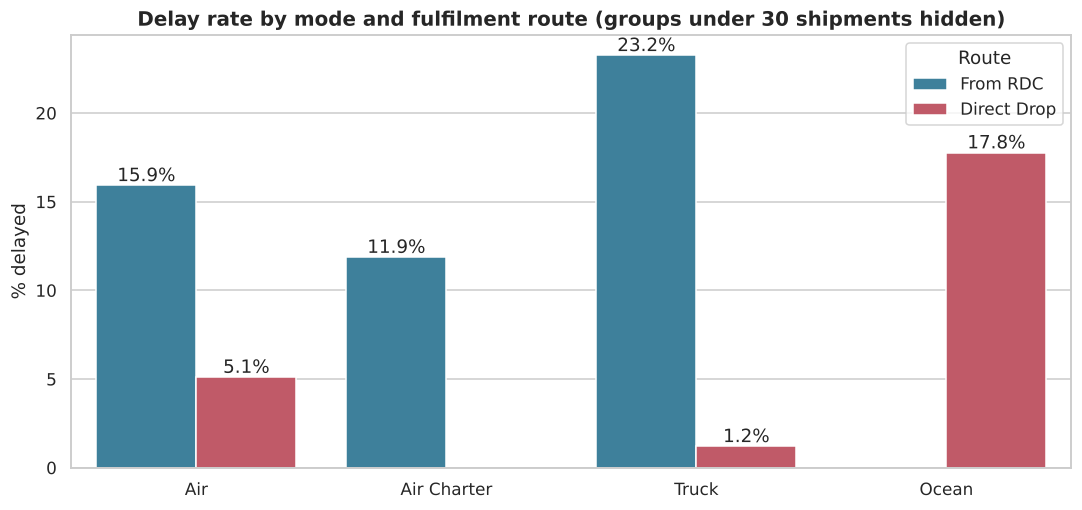

 fulfil_via shipment_mode  shipments  delay_rate
   From RDC         Truck       1910       23.20
Direct Drop         Ocean        366       17.80
   From RDC           Air       2545       15.90
   From RDC   Air Charter        632       11.90
Direct Drop           Air       3568        5.10
Direct Drop         Truck        920        1.20


In [23]:
# Chart - 7 : Delay rate by mode, split by fulfilment route
combo = delay_table(df.query("shipment_mode != 'Not recorded'"), ["fulfil_via", "shipment_mode"], min_n=30)
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=combo, x="shipment_mode", y="delay_rate", hue="fulfil_via", palette=[BLUE, RED], order=["Air", "Air Charter", "Truck", "Ocean"], ax=ax)
for p in ax.patches:
    if p.get_height() > 0: ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set(title="Delay rate by mode and fulfilment route (groups under 30 shipments hidden)", xlabel="", ylabel="% delayed"); ax.legend(title="Route")
plt.tight_layout(); plt.show()
print(combo[["fulfil_via", "shipment_mode", "shipments", "delay_rate"]].round(1).to_string(index=False))

##### 1. Why did you pick the specific chart?
Chart 6 hides a possible confounder, so the same bars are split by fulfilment route. A grouped bar puts the two routes side by side for each mode.

##### 2. What is/are the insight(s) found from the chart?
* **The picture flips.** On direct drops, Truck is the *best* mode (1.2% delayed) and Ocean the worst (17.8%).
* From the RDC, Truck is the *worst* (23.2%) and Air is 15.9%.
* The overall route gap is large: **From RDC 17.2% vs Direct Drop 5.3%**, chi-square p < 0.001, and an odds ratio of 4.8 in the logistic model.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
This is the most useful finding of the project. Trucks are not 'slow' in themselves; the RDC trucking leg is. Negative: moving RDC freight to another mode without fixing RDC handling would not remove the cause. Positive: the fix is targeted, namely RDC dispatch planning and regional trucking.

#### Chart - 8 : Delay rate by destination country  (H3)

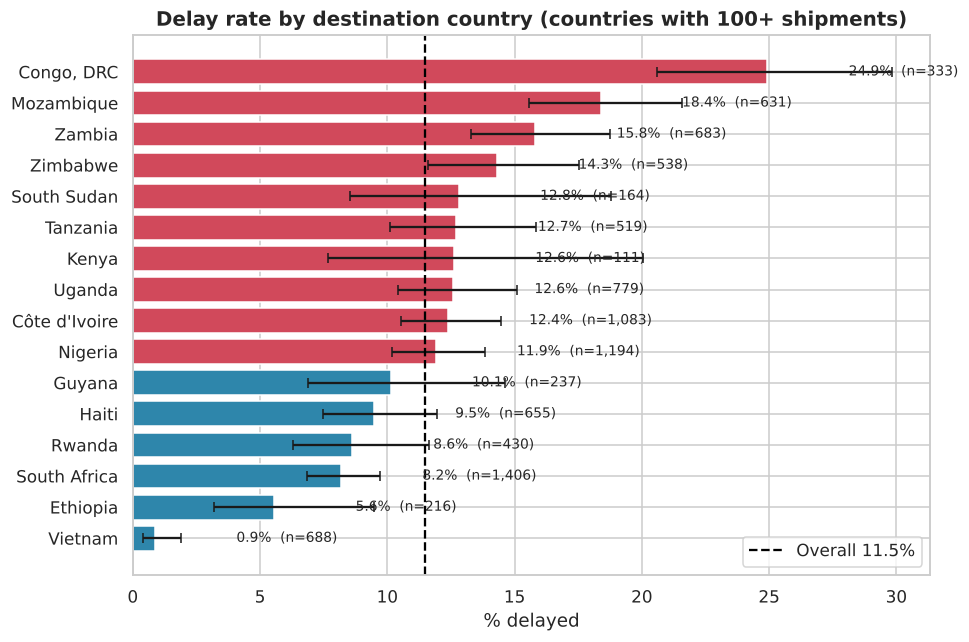

Chi-square test across 16 countries: chi2 = 213.2, p = 4.30e-37, Cramer's V = 0.15


In [24]:
# Chart - 8 : Delay rate by country (only countries with at least 100 shipments so that rates are stable)
vol = df["country"].value_counts(); big = vol[vol >= 100].index
t = delay_table(df[df["country"].isin(big)], "country").sort_values("delay_rate")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(t["country"], t["delay_rate"], color=[RED if r > overall else BLUE for r in t["delay_rate"]],
        xerr=[t["delay_rate"] - t["lo"], t["hi"] - t["delay_rate"]], capsize=3)
ax.axvline(overall, color="black", ls="--", label=f"Overall {overall:.1f}%")
for i, (r, n) in enumerate(zip(t["delay_rate"], t["shipments"])): ax.text(r + 3.2, i, f"{r:.1f}%  (n={n:,})", va="center", fontsize=9)
ax.set(title="Delay rate by destination country (countries with 100+ shipments)", xlabel="% delayed"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
res = chi_square(df[df["country"].isin(big)], "country")
print(f"Chi-square test across {len(big)} countries: chi2 = {res['chi2']:.1f}, p = {res['p']:.2e}, Cramer's V = {res['cramers_v']:.2f}")

##### 1. Why did you pick the specific chart?
Many categories with different sample sizes need a sorted horizontal bar. Red bars are above the overall rate, and the confidence-interval whiskers keep small countries honest.

##### 2. What is/are the insight(s) found from the chart?
* **Congo DRC 24.9%, Mozambique 18.4%, Zambia 15.8% and Zimbabwe 14.3%** are well above the 11.5% average.
* **Vietnam is at 0.9%**, Ethiopia 5.6%.
* Differences are real (chi-square p < 0.001). Burundi shows 38.8% but has only 98 shipments, so it is outside this chart.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
H3 is supported. Positive: planners can add country-specific buffer time (for example, plan DRC lanes with a longer promise date). Negative: the worst countries are also where supply interruption hurts most, so these lanes deserve a dedicated escalation owner.

#### Chart - 9 : Delay rate by vendor INCO term  (H5)

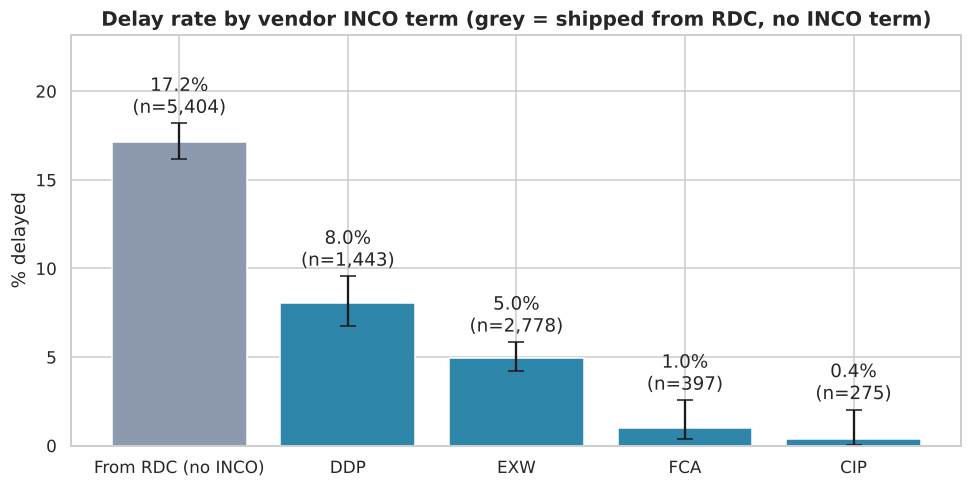

Direct Drop only, chi-square: chi2 = 50.2, dof = 3, p = 7.38e-11
DDP vs EXW (two-proportion z-test): 8.0% vs 5.0%, p = 9.17e-05


In [25]:
# Chart - 9 : Delay rate by INCO term (terms with 100+ shipments)
vol = df["inco_term"].value_counts(); keep = vol[vol >= 100].index
t = delay_table(df[df["inco_term"].isin(keep)], "inco_term")
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.bar(t["inco_term"], t["delay_rate"], color=[GREY if x.startswith("From RDC") else BLUE for x in t["inco_term"]],
       yerr=[t["delay_rate"] - t["lo"], t["hi"] - t["delay_rate"]], capsize=5)
for i, r in t.iterrows(): ax.text(i, r["hi"] + 0.6, f"{r['delay_rate']:.1f}%\n(n={r['shipments']:,})", ha="center")
ax.set(title="Delay rate by vendor INCO term (grey = shipped from RDC, no INCO term)", ylabel="% delayed", ylim=(0, t["hi"].max() + 5))
plt.tight_layout(); plt.show()
# Test only the Direct Drop orders, where an INCO term really exists
dd = df[(df["fulfil_via"] == "Direct Drop") & df["inco_term"].isin(keep)]
res = chi_square(dd, "inco_term")
print(f"Direct Drop only, chi-square: chi2 = {res['chi2']:.1f}, dof = {res['dof']}, p = {res['p']:.2e}")
a, b = dd[dd.inco_term == "DDP"]["is_delayed"], dd[dd.inco_term == "EXW"]["is_delayed"]
print("DDP vs EXW (two-proportion z-test):", f"{a.mean():.1%} vs {b.mean():.1%},", "p = %.2e" % stats.chi2_contingency(pd.crosstab(dd.inco_term.where(dd.inco_term.isin(['DDP','EXW'])), dd.is_delayed))[1])

##### 1. Why did you pick the specific chart?
INCO terms are categories with very different volumes. Bars with confidence intervals show which terms really differ, and greying the RDC bar prevents reading it as a contract term.

##### 2. What is/are the insight(s) found from the chart?
* Among direct drops, **CIP (0.4%) and FCA (1.0%) are almost never late**, EXW is 5.0% and **DDP is 8.0%**.
* DDP, where the vendor delivers to the client's door, is *more* delayed than EXW, which goes against the original hypothesis (H5).
* Differences are significant, but CIF, DAP and DDU have under 20 shipments each and are excluded.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
Positive: shifting suppliers from DDP toward FCA / CIP style terms is a measurable lever. Caution: terms are not randomly assigned. FCA/CIP vendors may simply be nearer or more experienced, so this is a pattern to test in a pilot, not proof that the term causes punctuality.

#### Chart - 10 : Delay rate by managing team  (H1)

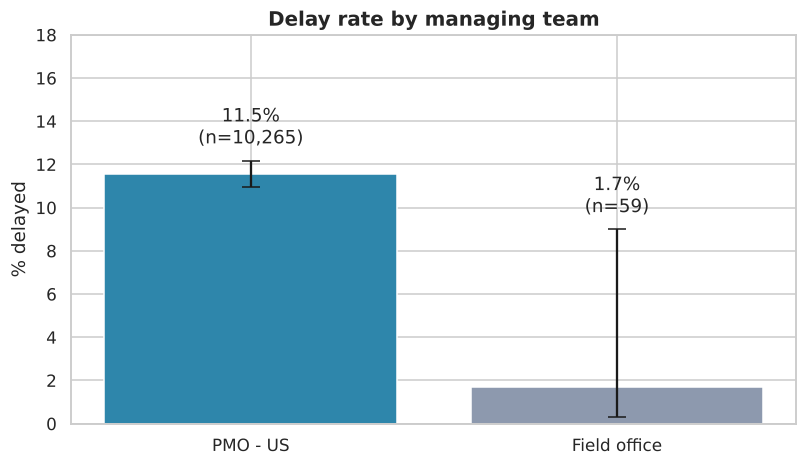

Fisher exact test: odds ratio = 7.6, p = 0.012   (only 59 field-office shipments)


In [26]:
# Chart - 10 : PMO - US vs field offices
t = delay_table(df, "managed_by")
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.bar(t["managed_by"], t["delay_rate"], color=[BLUE, GREY], yerr=[t["delay_rate"] - t["lo"], t["hi"] - t["delay_rate"]], capsize=6)
for i, r in t.iterrows(): ax.text(i, r["hi"] + 0.8, f"{r['delay_rate']:.1f}%\n(n={r['shipments']:,})", ha="center")
ax.set(title="Delay rate by managing team", ylabel="% delayed", ylim=(0, 18))
plt.tight_layout(); plt.show()
pmo, fo = df[df.managed_by == "PMO - US"]["is_delayed"], df[df.managed_by == "Field office"]["is_delayed"]
odds, p = stats.fisher_exact([[pmo.sum(), len(pmo) - pmo.sum()], [fo.sum(), len(fo) - fo.sum()]])
print(f"Fisher exact test: odds ratio = {odds:.1f}, p = {p:.3f}   (only {len(fo)} field-office shipments)")

##### 1. Why did you pick the specific chart?
Only two groups and one of them is tiny, so two bars with confidence intervals plus an exact test (Fisher) is the honest design; a chi-square would be unreliable with 59 rows.

##### 2. What is/are the insight(s) found from the chart?
* PMO - US: **11.5% delayed** (10,265 shipments). Field offices: **1.7%** (59 shipments, 1 delayed).
* The gap is statistically significant on its own (Fisher p = 0.012) but the field-office interval is very wide.
* In the logistic model (after controlling for route and mode) the field-office effect is **not significant** (p = 0.24).

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
H1 is **not confirmed**: PMO - US is the benchmark for 99% of volume, and the apparent field-office advantage is based on 59 shipments and disappears after controlling for route and mode. Recommendation: do not restructure teams from this evidence; collect more field-office data first.

#### Chart - 11 : Does order lead time matter?  (H4)

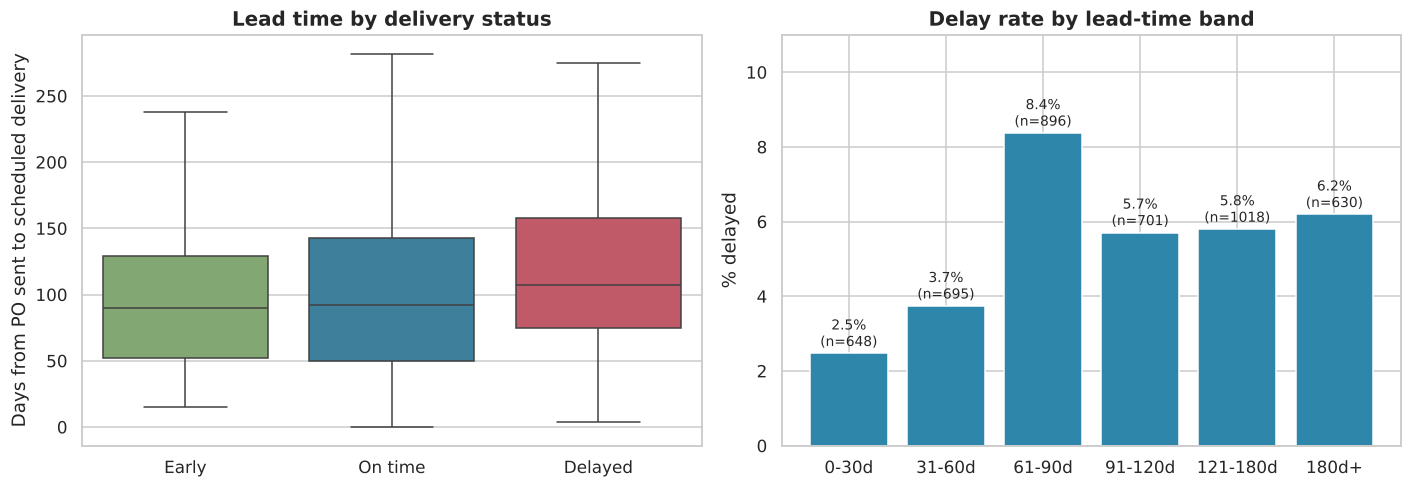

Median lead time: delayed 107 d vs not delayed 92 d | Mann-Whitney p = 0.0007
Spearman correlation lead time vs delay days = 0.041 (p = 0.006)


In [27]:
# Chart - 11 : Lead time (PO sent -> scheduled delivery), Direct Drop orders only
L = df.dropna(subset=["lead_days"]).copy()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
sns.boxplot(data=L, x="delivery_status", y="lead_days", order=["Early", "On time", "Delayed"], palette=PALETTE, showfliers=False, ax=ax[0])
ax[0].set(title="Lead time by delivery status", xlabel="", ylabel="Days from PO sent to scheduled delivery")
t = L.groupby("lead_band", observed=True)["is_delayed"].agg(["mean", "size"])
ax[1].bar(t.index.astype(str), t["mean"] * 100, color=BLUE)
for i, (m, n) in enumerate(zip(t["mean"], t["size"])): ax[1].text(i, m * 100 + 0.2, f"{m:.1%}\n(n={n})", ha="center", fontsize=9)
ax[1].set(title="Delay rate by lead-time band", ylabel="% delayed", ylim=(0, 11))
plt.tight_layout(); plt.show()
late, ok = L.loc[L.is_delayed == 1, "lead_days"], L.loc[L.is_delayed == 0, "lead_days"]
u = stats.mannwhitneyu(late, ok); rho = stats.spearmanr(L["lead_days"], L["delay_days"])
print(f"Median lead time: delayed {late.median():.0f} d vs not delayed {ok.median():.0f} d | Mann-Whitney p = {u.pvalue:.4f}")
print(f"Spearman correlation lead time vs delay days = {rho[0]:.3f} (p = {rho[1]:.3f})")

##### 1. Why did you pick the specific chart?
Lead time is numeric and the outcome is a category, so a box plot compares the two distributions and a banded bar shows the trend. The Mann-Whitney test is used because lead time is skewed.

##### 2. What is/are the insight(s) found from the chart?
* Delayed shipments had a **longer** median lead time (107 days) than on-time ones (92 days), Mann-Whitney p = 0.0007.
* Orders placed with under 30 days lead time are delayed only 2.5%; the peak is 8.4% at 61-90 days.
* The correlation with delay days is almost zero (Spearman 0.04), so lead time is a weak signal.
* Covers only 4,588 direct-drop shipments.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
H4 is **rejected**: giving vendors more time does not make delivery safer. Short, simple, urgent orders are the most reliable, possibly because they are prioritised. Longer orders are more likely to slip through the system. A longer promise date alone is not a fix.

#### Chart - 12 : Does heavier cargo cost more to insure?  (H6)

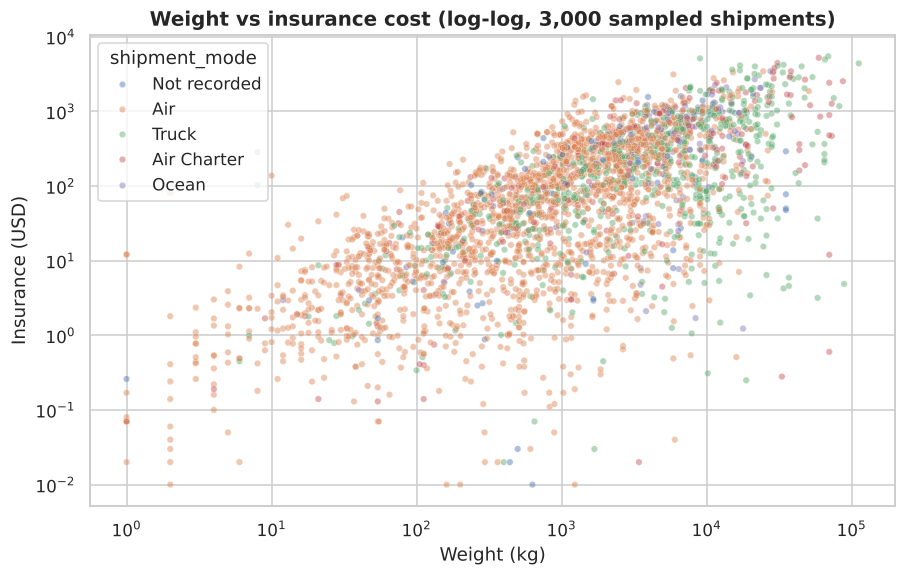

n = 8,401 | Pearson r = 0.53 | Spearman rho = 0.68


In [28]:
# Chart - 12 : Weight vs insurance cost, both on log scales
m = df.dropna(subset=["weight_kg", "insurance_usd"]); m = m[(m.weight_kg > 0) & (m.insurance_usd > 0)]
fig, ax = plt.subplots(figsize=(8.4, 5.4))
sns.scatterplot(data=m.sample(3000, random_state=1), x="weight_kg", y="insurance_usd", hue="shipment_mode", alpha=0.45, s=18, ax=ax)
ax.set(xscale="log", yscale="log", title="Weight vs insurance cost (log-log, 3,000 sampled shipments)", xlabel="Weight (kg)", ylabel="Insurance (USD)")
plt.tight_layout(); plt.show()
print(f"n = {len(m):,} | Pearson r = {np.corrcoef(m.weight_kg, m.insurance_usd)[0, 1]:.2f} | Spearman rho = {stats.spearmanr(m.weight_kg, m.insurance_usd)[0]:.2f}")

##### 1. Why did you pick the specific chart?
Two numeric variables call for a scatter plot. Log axes are essential because both span five orders of magnitude, and colouring by mode shows whether any group behaves differently.

##### 2. What is/are the insight(s) found from the chart?
* There is a clear upward cloud: **Spearman rho = 0.68** (Pearson 0.53) across 8,401 shipments.
* But the cloud is wide; heavy shipments can have small insurance and the reverse.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
H6 looks **supported** here, but this chart alone is misleading. Chart 13 shows weight is a stand-in for something else. Stopping at this chart would lead to the wrong rule ('insure by weight').

#### Chart - 13 : What really drives insurance cost?

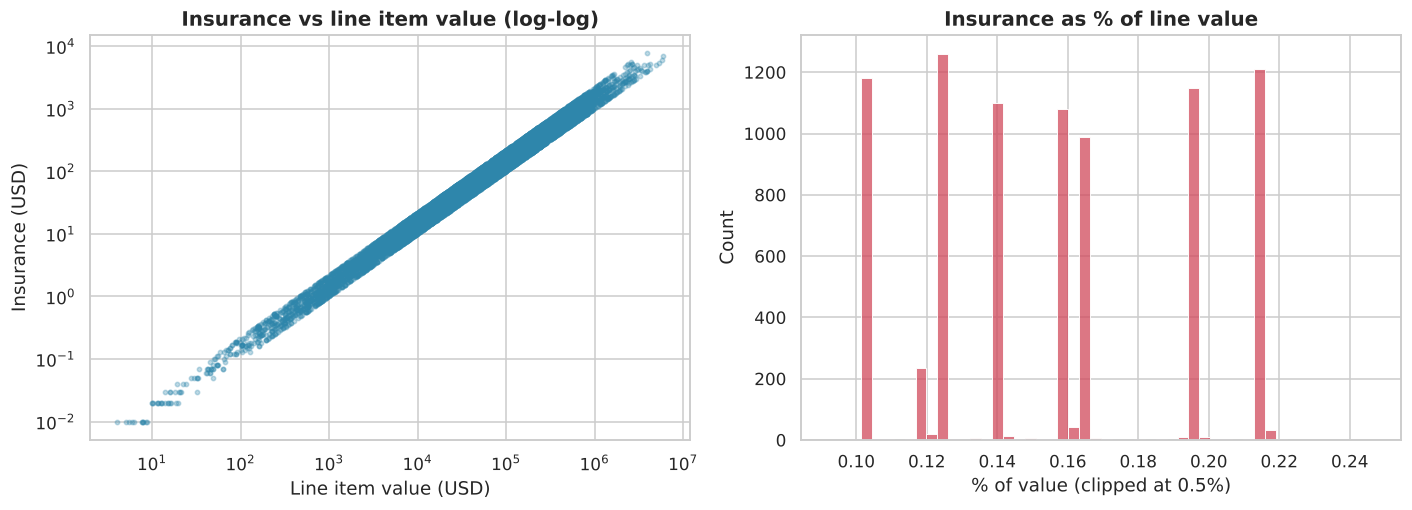

Spearman insurance vs line value   : 0.993
Spearman insurance vs weight       : 0.675
Partial correlation weight-insurance controlling for value: -0.098
Median insurance rate: 0.160% of line value


In [29]:
# Chart - 13 : Insurance vs line item value (log-log) and the typical insurance rate
m = df.dropna(subset=["weight_kg", "insurance_usd", "line_value"]); m = m[(m.weight_kg > 0) & (m.insurance_usd > 0) & (m.line_value > 0)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].scatter(m["line_value"], m["insurance_usd"], s=8, alpha=0.3, color=BLUE)
ax[0].set(xscale="log", yscale="log", title="Insurance vs line item value (log-log)", xlabel="Line item value (USD)", ylabel="Insurance (USD)")
sns.histplot(m["insurance_pct_value"].clip(upper=0.5), bins=50, color=RED, ax=ax[1])
ax[1].set(title="Insurance as % of line value", xlabel="% of value (clipped at 0.5%)")
plt.tight_layout(); plt.show()
# Partial correlation: weight vs insurance AFTER removing what value explains (residuals of log-log regressions)
lw, lv, li = np.log(m.weight_kg), np.log(m.line_value), np.log(m.insurance_usd)
res_w = lw - np.polyval(np.polyfit(lv, lw, 1), lv); res_i = li - np.polyval(np.polyfit(lv, li, 1), lv)
print(f"Spearman insurance vs line value   : {stats.spearmanr(m.line_value, m.insurance_usd)[0]:.3f}")
print(f"Spearman insurance vs weight       : {stats.spearmanr(m.weight_kg, m.insurance_usd)[0]:.3f}")
print(f"Partial correlation weight-insurance controlling for value: {np.corrcoef(res_w, res_i)[0, 1]:.3f}")
print(f"Median insurance rate: {m.insurance_pct_value.median():.3f}% of line value")

##### 1. Why did you pick the specific chart?
To test whether weight is the real driver, insurance is plotted against the other obvious candidate, value. A partial correlation removes the effect of value from both sides.

##### 2. What is/are the insight(s) found from the chart?
* Insurance follows line value almost perfectly (**Spearman 0.99**); the points sit on a thin straight band.
* The typical insurance charge is **about 0.16% of line value**.
* After controlling for value, the weight-insurance partial correlation is **-0.10** (essentially none, slightly negative).

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
H6 is only **partly true**: heavier shipments cost more to insure because they usually carry more goods, not because of weight. Positive: insurance cost can be forecast from value with a single rate. Negative: any plan that tries to cut insurance by reducing weight will not work.

#### Chart - 14 : Delay rate over the years (interactive Plotly)

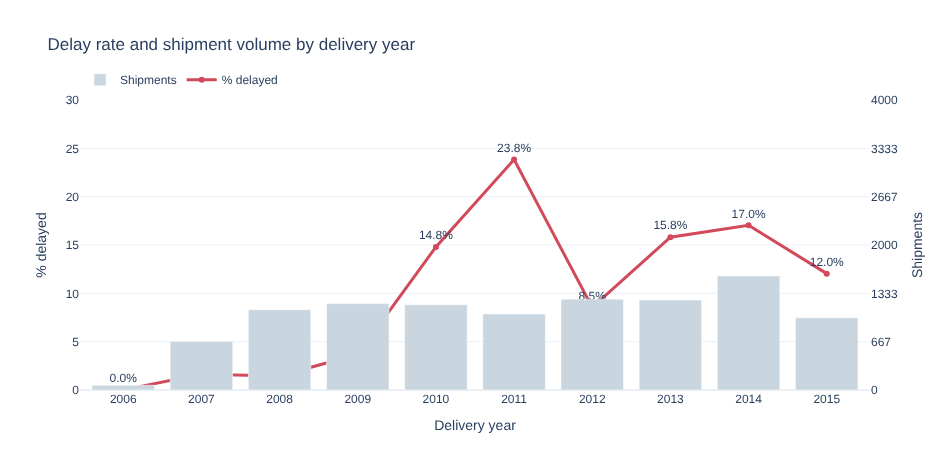

In [30]:
# Chart - 14 : Delay rate and volume by delivery year (interactive in Colab: hover for details)
yr = df.groupby("delivery_year").agg(shipments=("ID", "count"), delay_rate=("is_delayed", "mean")).reset_index()
yr["delay_rate"] *= 100
fig = go.Figure()
fig.add_bar(x=yr["delivery_year"], y=yr["shipments"], name="Shipments", marker_color="#C9D6DF", yaxis="y2")
fig.add_scatter(x=yr["delivery_year"], y=yr["delay_rate"], name="% delayed", mode="lines+markers+text", text=yr["delay_rate"].round(1).astype(str) + "%",
                textposition="top center", line=dict(color=RED, width=3))
fig.update_layout(title="Delay rate and shipment volume by delivery year", template="plotly_white", width=950, height=470,
                  xaxis=dict(dtick=1, title="Delivery year"), yaxis=dict(title="% delayed", range=[0, 30]),
                  yaxis2=dict(title="Shipments", overlaying="y", side="right", showgrid=False, range=[0, 4000]), legend=dict(orientation="h", y=1.12))
fig.show()

##### 1. Why did you pick the specific chart?
A trend over time calls for a line. Volume is added as light bars on a second axis, so the reader can see whether a change in rate comes with a change in volume. Plotly is used so that values can be inspected on hover.

##### 2. What is/are the insight(s) found from the chart?
* Delay was nearly zero until 2009 (1.6% in 2007, 3.7% in 2009), then **jumped to 14.8% in 2010 and peaked at 23.8% in 2011**.
* It fell to 8.5% in 2012, then rebounded to between 12.0% and 17.0% in 2013-2015.
* Volume did not change as sharply, so the jump is not a volume effect.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
Two readings are possible and the data cannot separate them: real performance got worse after 2009, or delivery dates were recorded differently before 2010. Because 61% of all rows show delay = 0, I treat the early years as unreliable. Negative: any model trained on all years would mix both regimes. Recommended: audit how the delivery date was captured.

#### Chart - 15 : Freight cost per kg by shipment mode

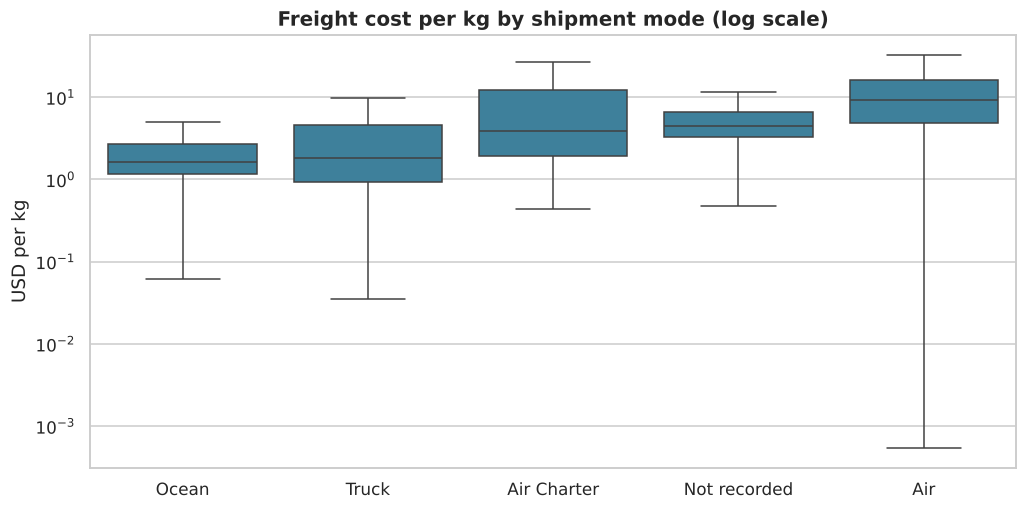

               median  count
shipment_mode               
Ocean            1.62    322
Truck            1.82   1811
Air Charter      3.85    572
Not recorded     4.40    311
Air              9.35   5476


In [31]:
# Chart - 15 : Freight cost per kg by mode (log scale)
f = df.dropna(subset=["freight_per_kg"]); f = f[f.freight_per_kg > 0]
order = f.groupby("shipment_mode")["freight_per_kg"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.boxplot(data=f, x="shipment_mode", y="freight_per_kg", order=order, color=BLUE, showfliers=False, ax=ax)
ax.set(yscale="log", title="Freight cost per kg by shipment mode (log scale)", xlabel="", ylabel="USD per kg")
plt.tight_layout(); plt.show()
print(f.groupby("shipment_mode")["freight_per_kg"].agg(["median", "count"]).sort_values("median").round(2))

##### 1. Why did you pick the specific chart?
Cost per kg is numeric and mode is categorical, so a box plot compares the full spread per mode. Dividing by weight makes light and heavy shipments comparable.

##### 2. What is/are the insight(s) found from the chart?
* Median cost per kg: **Air $9.35**, Air Charter $3.85, Truck $1.82, **Ocean $1.62**.
* Air costs about **5 times** as much per kg as Truck and 6 times as much as Ocean.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
This is the trade-off behind chart 6: Air is the most punctual common mode, but also by far the most expensive. Moving direct-drop freight from Truck to Air would be wasteful (Truck is already the most reliable there). The money-saving idea is to keep Air only where the delay risk justifies it.

### **M - Multivariate analysis**

#### Chart - 16 : Correlation heatmap

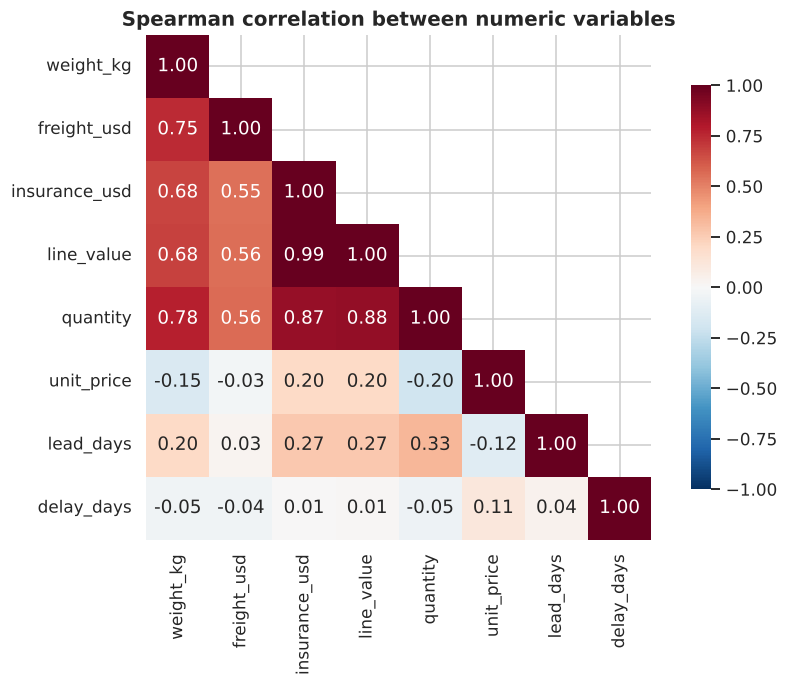

In [32]:
# Chart - 16 : Spearman correlation heatmap (rank correlation is robust to the heavy skew)
cols = ["weight_kg", "freight_usd", "insurance_usd", "line_value", "quantity", "unit_price", "lead_days", "delay_days"]
corr = df[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 6.4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, mask=np.triu(np.ones_like(corr, dtype=bool), 1), square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Spearman correlation between numeric variables")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
A heatmap shows every pairwise relationship at once, which makes it the quickest way to spot variables worth a closer look. Spearman is used because weight, cost and value are heavily skewed.

##### 2. What is/are the insight(s) found from the chart?
* Value, quantity, insurance, weight and freight are strongly related to each other (size of the shipment moves them all).
* **Delay days has almost no correlation with any numeric variable** (all values near 0).
* Insurance vs line value is the strongest pair (about 0.99).

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
Positive: the numeric features are redundant (any one of them stands in for 'shipment size'). Negative: delay cannot be explained by cost, weight or size, so delay prevention must focus on categories (route, mode, country), not on numbers.

#### Chart - 17 : Route -> mode -> delay rate (interactive Plotly sunburst)

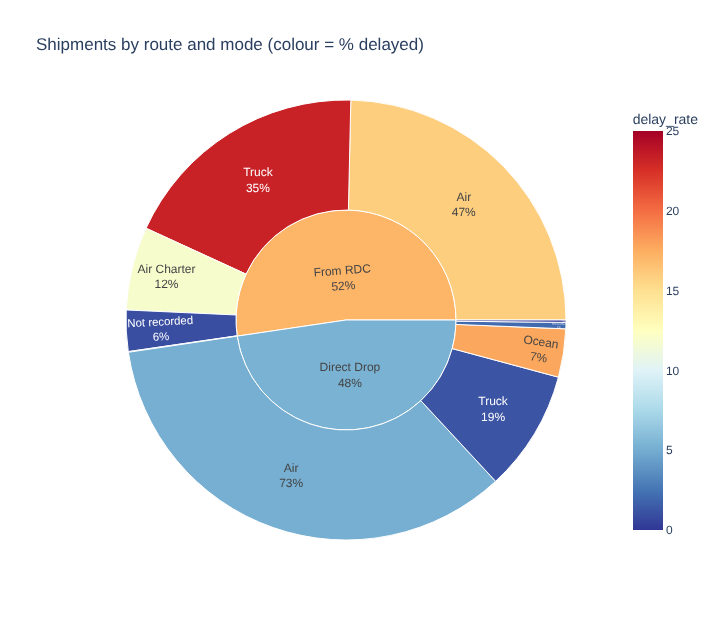

In [33]:
# Chart - 17 : Sunburst: size = number of shipments, colour = delay rate
sb = df.groupby(["fulfil_via", "shipment_mode"]).agg(shipments=("ID", "count"), delay_rate=("is_delayed", "mean")).reset_index()
sb["delay_rate"] *= 100
fig = px.sunburst(sb, path=["fulfil_via", "shipment_mode"], values="shipments", color="delay_rate", color_continuous_scale="RdYlBu_r",
                  range_color=(0, 25), title="Shipments by route and mode (colour = % delayed)", width=720, height=620)
fig.update_traces(textinfo="label+percent parent", hovertemplate="%{label}<br>Shipments: %{value:,}<br>Delay rate: %{color:.1f}%")
fig.show()

##### 1. Why did you pick the specific chart?
A sunburst keeps the hierarchy (route, then mode) visible while showing volume as size and risk as colour, in one picture that can be explored by hovering.

##### 2. What is/are the insight(s) found from the chart?
* The biggest slice is **From RDC / Air** and the reddest slices are **From RDC / Truck** and **Direct Drop / Ocean**.
* Direct Drop / Truck and Direct Drop / Air are cool blue even though they are large.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
It shows where effort pays most: RDC trucking is both large and late. Positive: a single, visible hotspot. Negative: it is also a big share of volume, so changes there need careful piloting.

#### Chart - 18 : Country x mode delay heatmap

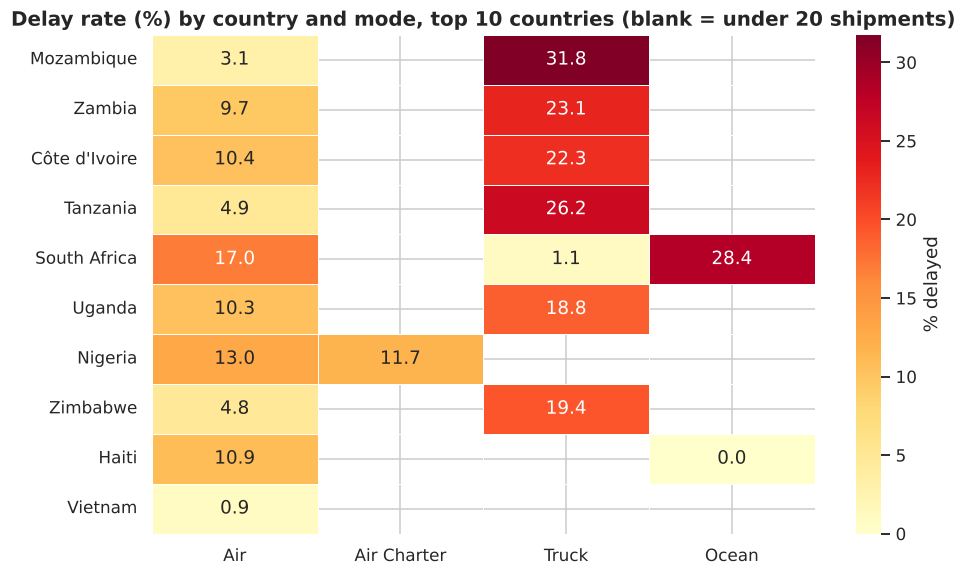

In [34]:
# Chart - 18 : Delay rate for the 10 busiest countries across modes (cells with fewer than 20 shipments are blanked)
top10 = df["country"].value_counts().head(10).index
sub = df[df["country"].isin(top10) & df["shipment_mode"].isin(["Air", "Air Charter", "Truck", "Ocean"])]
rate = sub.pivot_table(index="country", columns="shipment_mode", values="is_delayed", aggfunc="mean") * 100
n = sub.pivot_table(index="country", columns="shipment_mode", values="is_delayed", aggfunc="count")
rate = rate.where(n >= 20).reindex(columns=["Air", "Air Charter", "Truck", "Ocean"])
rate = rate.loc[rate.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(9, 5.4))
sns.heatmap(rate, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=.5, cbar_kws={"label": "% delayed"}, ax=ax)
ax.set(title="Delay rate (%) by country and mode, top 10 countries (blank = under 20 shipments)", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
Two categorical drivers (country and mode) against one rate: a heatmap is the natural form, and blanking small cells prevents over-reading noise.

##### 2. What is/are the insight(s) found from the chart?
* **Truck is the hottest column in most countries**: Mozambique 31.8%, Tanzania 26.2%, Zambia 23.1%, Cote d'Ivoire 22.3%, Zimbabwe 19.4%, Uganda 18.8%.
* **South Africa is the exception**: Truck only 1.1%, but Ocean 28.4% and Air 17.0%.
* Air is mostly calm (Mozambique 3.1%, Tanzania 4.9%, Zimbabwe 4.8%); Vietnam is only observed on Air at 0.9%.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
The same country can be fine by Air and bad by Truck (Mozambique 3.1% vs 31.8%), so the delay problem sits in specific country-and-mode lanes, which matches the RDC trucking finding of chart 7. Negative: many cells are blank because some country-mode pairs hardly exist, so lane-level conclusions stay limited to the cells shown.

#### Chart - 19 : Pair plot of the size variables

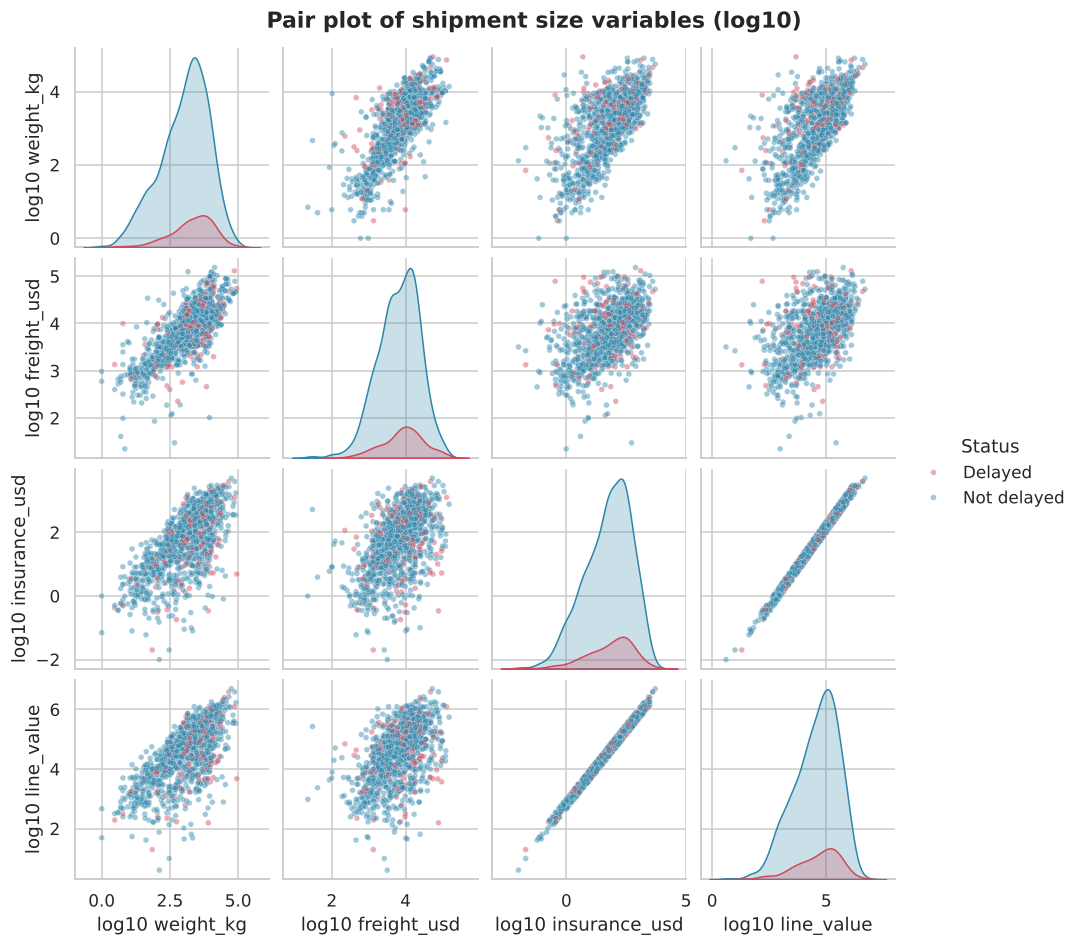

In [35]:
# Chart - 19 : Pair plot (log10 values, 1,200 sampled shipments) coloured by delayed / not delayed
pp = df.dropna(subset=["weight_kg", "freight_usd", "insurance_usd", "line_value"])
pp = pp[(pp[["weight_kg", "freight_usd", "insurance_usd", "line_value"]] > 0).all(axis=1)].sample(1200, random_state=7)
pp_log = np.log10(pp[["weight_kg", "freight_usd", "insurance_usd", "line_value"]]).add_prefix("log10 ")
pp_log["Status"] = np.where(pp["is_delayed"] == 1, "Delayed", "Not delayed")
sns.pairplot(pp_log, hue="Status", palette={"Delayed": RED, "Not delayed": BLUE}, plot_kws={"alpha": 0.45, "s": 14}, diag_kind="kde", height=2.1)
plt.suptitle("Pair plot of shipment size variables (log10)", y=1.02, fontweight="bold")
plt.show()

##### 1. Why did you pick the specific chart?
A pair plot shows every scatter and every distribution together, and the colour tests the final question: do delayed shipments sit in a different region of the size space?

##### 2. What is/are the insight(s) found from the chart?
* Size variables line up along tight diagonals (freight, insurance, value and weight rise together).
* **Red (delayed) and blue (not delayed) points overlap almost completely** and have the same distributions.

##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?
Confirms chart 16: size does not separate delayed from on-time shipments. Positive: the planning model can ignore size. Negative: no numeric feature in this dataset can predict delay; better data (carrier, port, customs, weather) would be needed for a predictive model.

## ***Hypothesis testing summary and logistic-regression check***

In [36]:
# Summary of every test run above, in one table
def pval(p): return "< 0.001" if p < 0.001 else f"{p:.3f}"
vol = df["country"].value_counts(); big = vol[vol >= 100].index
dd = df[(df["fulfil_via"] == "Direct Drop") & df["inco_term"].isin(["DDP", "EXW", "FCA", "CIP"])]
pmo, fo = df[df.managed_by == "PMO - US"]["is_delayed"], df[df.managed_by == "Field office"]["is_delayed"]
L = df.dropna(subset=["lead_days"]); m = df.dropna(subset=["weight_kg", "insurance_usd"]); m = m[(m.weight_kg > 0) & (m.insurance_usd > 0)]
rows = [
    ("H1 Managing team", "Fisher exact", pval(stats.fisher_exact([[pmo.sum(), len(pmo)-pmo.sum()], [fo.sum(), len(fo)-fo.sum()]])[1]), "Significant raw, but only 59 field-office rows; not significant after controls"),
    ("H2/H7 Shipment mode", "Chi-square", pval(chi_square(df, "shipment_mode")["p"]), "Supported: Air best, Ocean/Truck worst (reverses by route)"),
    ("H3 Destination country", "Chi-square (100+ shipments)", pval(chi_square(df[df.country.isin(big)], "country")["p"]), "Supported: DRC, Mozambique, Zambia worst; Vietnam best"),
    ("H4 PO-to-delivery lead time", "Mann-Whitney", pval(stats.mannwhitneyu(L[L.is_delayed == 1].lead_days, L[L.is_delayed == 0].lead_days).pvalue), "Rejected: longer lead time is not safer; effect is weak"),
    ("H5 INCO term", "Chi-square (Direct Drop)", pval(chi_square(dd, "inco_term")["p"]), "Supported, but DDP is worse than EXW (opposite of hypothesis)"),
    ("H6 Weight vs insurance", "Spearman", pval(stats.spearmanr(m.weight_kg, m.insurance_usd)[1]), f"Correlated (rho {stats.spearmanr(m.weight_kg, m.insurance_usd)[0]:.2f}) but driven by value, not weight"),
]
pd.DataFrame(rows, columns=["Hypothesis", "Test", "p-value", "Conclusion"])

,Hypothesis,Test,p-value,Conclusion
0,H1 Managing team,Fisher exact,0.012,"Significant raw, but only 59 field-office rows..."
1,H2/H7 Shipment mode,Chi-square,< 0.001,"Supported: Air best, Ocean/Truck worst (revers..."
2,H3 Destination country,Chi-square (100+ shipments),< 0.001,"Supported: DRC, Mozambique, Zambia worst; Viet..."
3,H4 PO-to-delivery lead time,Mann-Whitney,< 0.001,Rejected: longer lead time is not safer; effec...
4,H5 INCO term,Chi-square (Direct Drop),< 0.001,"Supported, but DDP is worse than EXW (opposite..."
5,H6 Weight vs insurance,Spearman,< 0.001,"Correlated (rho 0.68) but driven by value, not..."


In [37]:
# Logistic regression: which factors still matter when considered TOGETHER? (odds ratios; 1 = no effect)
model = smf.logit('is_delayed ~ C(fulfil_via, Treatment("Direct Drop")) + C(shipment_mode, Treatment("Air")) + C(managed_by, Treatment("PMO - US"))', data=df).fit(disp=0)
out = pd.DataFrame({"odds_ratio": np.exp(model.params), "p_value": model.pvalues}).drop("Intercept")
out.index = ["From RDC (vs Direct Drop)", "Air Charter (vs Air)", "Mode not recorded (vs Air)", "Ocean (vs Air)", "Truck (vs Air)", "Field office (vs PMO - US)"]
print(f"Pseudo R-squared: {model.prsquared:.3f}   (small: these factors explain only part of why shipments are late)")
out.round(3)

Pseudo R-squared: 0.080   (small: these factors explain only part of why shipments are late)


,odds_ratio,p_value
From RDC (vs Direct Drop),4.79,0.00
Air Charter (vs Air),0.64,0.00
Mode not recorded (vs Air),0.06,0.00
Ocean (vs Air),4.74,0.00
Truck (vs Air),1.30,0.00
Field office (vs PMO - US),0.30,0.24


**Reading the model:** being shipped **from the RDC multiplies the odds of delay by 4.8**, and Ocean by 4.7, relative to Direct Drop and Air. Truck is only 1.3 times Air once the route is known, and the field-office difference is not significant. The pseudo R-squared of 0.08 says these factors explain a minority of delay behaviour; most of it comes from things this dataset does not contain.

## ***5. Solution to Business Objective***

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

1. **Fix the RDC leg first.** Shipments from the regional distribution centre are delayed 17.2% of the time against 5.3% for direct drops, and RDC trucking is worst at 23.2%. Review RDC dispatch planning, stock availability and regional trucking contracts.
2. **Plan with country-specific buffers.** For Congo DRC, Mozambique, Zambia and Zimbabwe, add buffer to the promised date; use the median (12 days) and 90th percentile (51 days) of delays, not the average.
3. **Prefer FCA / CIP style terms** where vendors and lanes allow it. They show under 1% delay among direct drops; test it as a pilot before making it a rule.
4. **Do not buy speed blindly.** Air costs about 5x Truck per kg. Keep Air for lanes where the delay risk justifies it; Truck is already the most reliable direct-drop mode.
5. **Forecast insurance from value, not weight** (about 0.16% of line value).
6. **Audit data capture.** 61% of shipments show delay exactly 0 and delays are near zero before 2010. Fix how delivery dates are recorded and capture carrier, port and customs data to make delay predictable later.

# **Conclusion**

FedEx Logistics delivers **88.5%** of the 10,324 shipments on or before the schedule. The 11.5% that are late concentrate in a small number of places: **shipments dispatched from the regional distribution centre** (odds of delay 4.8x higher), **Ocean freight**, and **destinations such as Congo DRC, Mozambique and Zambia**. Shipment mode only tells part of the story: Truck is the most reliable mode for direct drops but the least reliable from the RDC. FCA and CIP contracts are almost never late, a longer order lead time does not protect against delay, and the PMO - US versus field-office difference is based on too few shipments to act on. Insurance cost follows line-item value (about 0.16% of value) rather than weight.

The most important limitation is data quality: more than six in ten shipments show a delivery date equal to the schedule and almost no delay before 2010, so recording practice may be shaping the results. The next steps are a data audit, a pilot of FCA/CIP terms and RDC process changes on the worst lanes, and then a predictive model once carrier, port and customs data are available.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***